Loading California Housing dataset...
Original Dataset Shape: (20640, 9)


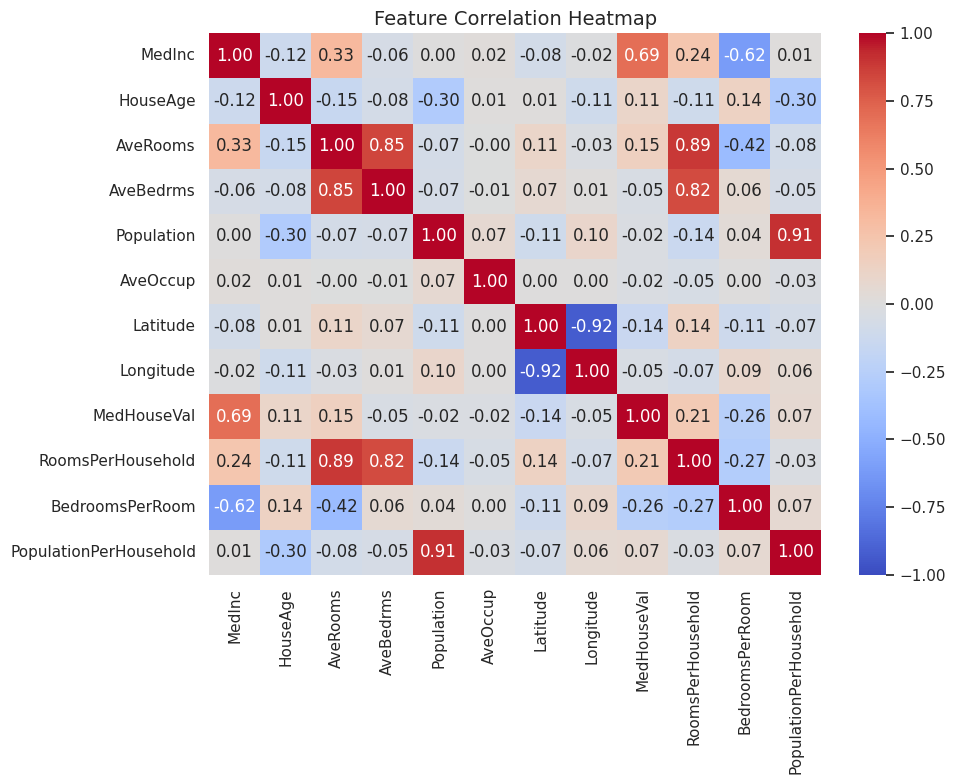

Training OLS, Ridge, and Lasso models (this may take a few seconds)...

          REGRESSION BENCHMARK REPORT             
                       Model     RMSE      MAE  R² Score
Ordinary Least Squares (OLS) 0.673817 0.487439  0.653521
        Ridge (alpha=40.370) 0.674021 0.487355  0.653311
         Lasso (alpha=0.003) 0.674436 0.487597  0.652884



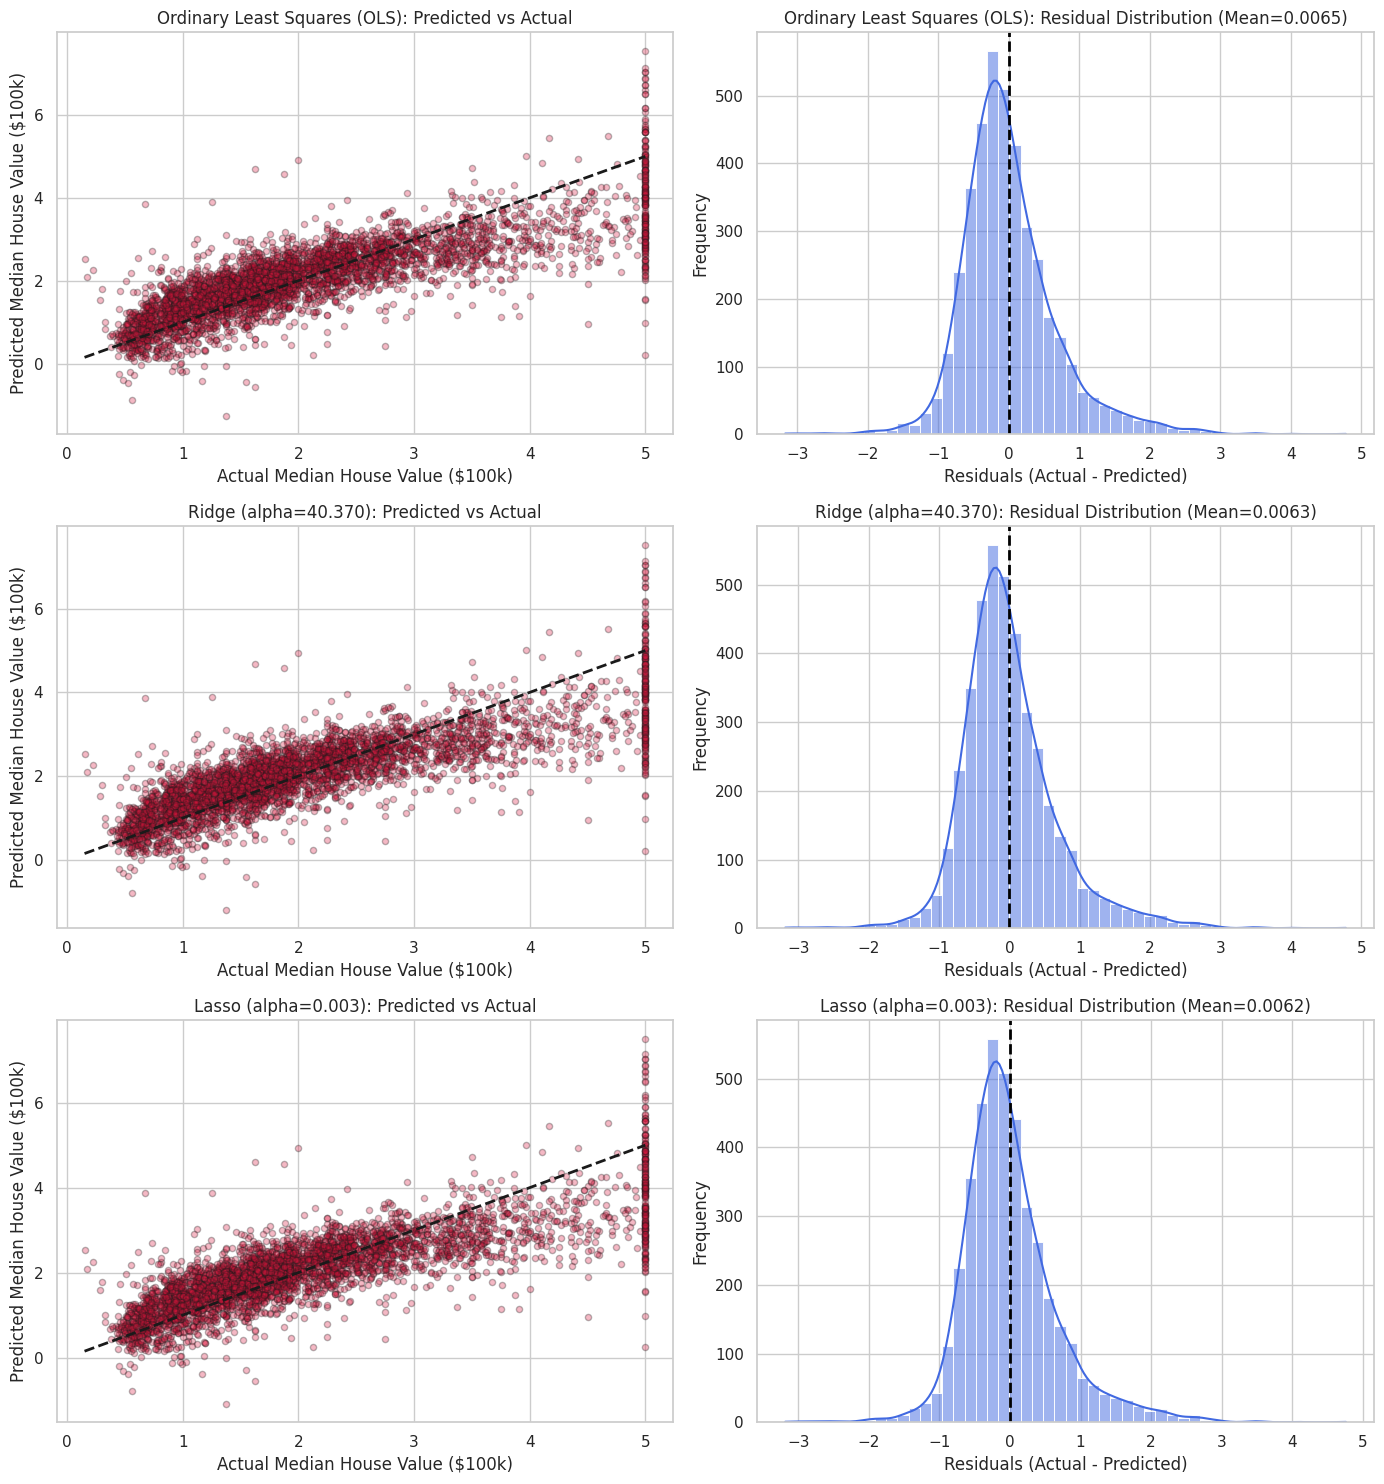

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Enable inline plots in Colab
%matplotlib inline
sns.set_theme(style="whitegrid")

# 1. Load California Housing Dataset
print("Loading California Housing dataset...")
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

print(f"Original Dataset Shape: {df.shape}")

# 2. Feature Engineering (Interaction Terms & Ratios)
df['RoomsPerHousehold'] = df['AveRooms'] / df['AveOccup']
df['BedroomsPerRoom'] = df['AveBedrms'] / df['AveRooms']
df['PopulationPerHousehold'] = df['Population'] / df['AveOccup']

# Separate Features (X) and Target (y)
X = df.drop(columns=['MedHouseVal'])
y = df['MedHouseVal']

# 3. Exploratory Data Analysis & Handling Multicollinearity
plt.figure(figsize=(10, 8))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Feature Correlation Heatmap", fontsize=14)
plt.tight_layout()
plt.show()

# 4. Define Preprocessing Pipeline for Continuous Attributes
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features)
    ]
)

# 5. Train / Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 6. Model Setup & Hyperparameter Tuning via GridSearchCV
alphas = np.logspace(-3, 3, 100)

# Ordinary Least Squares (OLS) Baseline Pipeline
ols_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Ridge Regression (L2 Regularization) Pipeline
ridge_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Ridge())
])
ridge_cv = GridSearchCV(
    ridge_pipeline,
    param_grid={'regressor__alpha': alphas},
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

# Lasso Regression (L1 Regularization) Pipeline
lasso_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Lasso(max_iter=10000, random_state=42))
])
lasso_cv = GridSearchCV(
    lasso_pipeline,
    param_grid={'regressor__alpha': alphas},
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

# Fit Models
print("Training OLS, Ridge, and Lasso models (this may take a few seconds)...")
ols_pipeline.fit(X_train, y_train)
ridge_cv.fit(X_train, y_train)
lasso_cv.fit(X_train, y_train)

# Collect Best Estimators
models = {
    "Ordinary Least Squares (OLS)": ols_pipeline,
    f"Ridge (alpha={ridge_cv.best_params_['regressor__alpha']:.3f})": ridge_cv.best_estimator_,
    f"Lasso (alpha={lasso_cv.best_params_['regressor__alpha']:.3f})": lasso_cv.best_estimator_
}

# 7. Model Evaluation & Benchmarking
evaluation_results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    evaluation_results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R² Score": r2
    })

results_df = pd.DataFrame(evaluation_results)
print("\n==================================================")
print("          REGRESSION BENCHMARK REPORT             ")
print("==================================================")
print(results_df.to_string(index=False))
print("==================================================\n")

# 8. Diagnostic Visualizations (Predicted vs Actual & Residual Distributions)
fig, axes = plt.subplots(len(models), 2, figsize=(14, 5 * len(models)))

for idx, (name, y_pred) in enumerate(predictions.items()):
    residuals = y_test - y_pred

    # Subplot A: Predicted vs Actual Scatter Plot
    ax_pred = axes[idx, 0]
    ax_pred.scatter(y_test, y_pred, alpha=0.3, color='crimson', edgecolors='k', s=20)
    ax_pred.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
    ax_pred.set_title(f"{name}: Predicted vs Actual")
    ax_pred.set_xlabel("Actual Median House Value ($100k)")
    ax_pred.set_ylabel("Predicted Median House Value ($100k)")

    # Subplot B: Residual Distribution Curve
    ax_res = axes[idx, 1]
    sns.histplot(residuals, kde=True, ax=ax_res, color='royalblue', bins=50)
    ax_res.axvline(0, color='black', linestyle='--', lw=2)
    ax_res.set_title(f"{name}: Residual Distribution (Mean={residuals.mean():.4f})")
    ax_res.set_xlabel("Residuals (Actual - Predicted)")
    ax_res.set_ylabel("Frequency")

plt.tight_layout()
plt.show()